# Day 10: Machine Learning with Scikit-learn

## Introduction

Machine Learning allows systems to learn patterns from existing data and use them to make predictions on unseen data. In this task, Linear Regression is used to study the relationship between years of experience and salary. The dataset is explored and cleaned before splitting it into training and testing sets, training the model, and evaluating its predictions.

### Objective
Understand the Machine Learning workflow by building a Linear Regression model that predicts salary based on years of experience.

### Workflow
1. Load the dataset.
2. Perform Exploratory Data Analysis (EDA).
3. Preprocess the data.
4. Split the data into training and testing sets.
5. Train the model using `fit()`.
6. Generate predictions using `predict()`.
7. Evaluate the model and save it.

### Dataset
The dataset contains years of experience and corresponding salary values.

## 1. Loading the Dataset

Pandas is used to load the CSV file into a DataFrame. Matplotlib is used for visualization, while Scikit-learn provides the tools required to split the data, train the model, and evaluate its predictions.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the CSV file
df = pd.read_csv("Salary_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 2. Exploratory Data Analysis (EDA)

EDA helps examine the dataset before model training. It includes inspecting the dataset's dimensions, column names, data types, statistical summaries, missing values, duplicate rows, and relationships between variables.

This stage helps identify potential data-quality issues and understand whether the selected feature may be useful for predicting the target.

In [2]:
# View the first five rows
print("First five rows:")
display(df.head())

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Inspect column names and data types
print("\nDataset information:")
df.info()

# View statistical summaries
print("\nStatistical summary:")
display(df.describe())

# Check for missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

First five rows:


,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344
1,1,1.4,46206
2,2,1.6,37732
3,3,2.1,43526
4,4,2.3,39892


Dataset shape: (30, 3)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     int64  
dtypes: float64(1), int64(2)
memory usage: 852.0 bytes

Statistical summary:


,Unnamed: 0,YearsExperience,Salary
count,30.000000,30.000000,30.000000
mean,14.500000,5.413333,76004.000000
std,8.803408,2.837888,27414.429785
min,0.000000,1.200000,37732.000000
25%,7.250000,3.300000,56721.750000
50%,14.500000,4.800000,65238.000000
75%,21.750000,7.800000,100545.750000
max,29.000000,10.600000,122392.000000



Missing values in each column:
Unnamed: 0         0
YearsExperience    0
Salary             0
dtype: int64

Number of duplicate rows: 0


### Visualizing the Feature-Target Relationship

A scatter plot shows how salary varies with years of experience. An approximately linear relationship would support trying Linear Regression, although the model's predictive performance must still be evaluated.

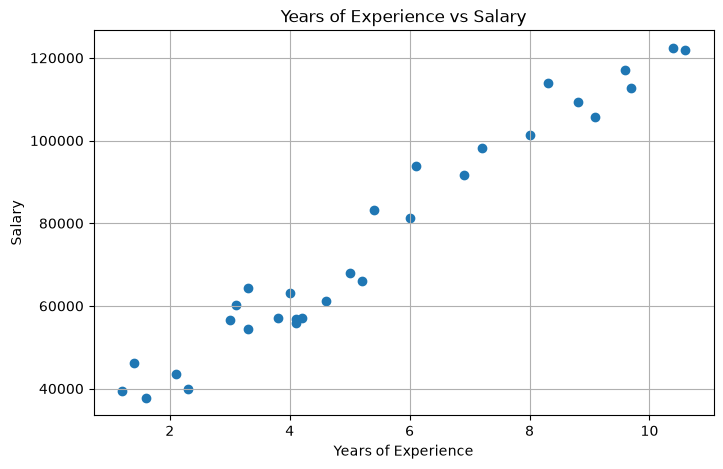

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(df["YearsExperience"], df["Salary"])

plt.title("Years of Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.grid(True)

plt.show()

## 3. Data Preprocessing

Data preprocessing prepares the dataset for Machine Learning. Unnecessary columns should be removed, and the feature and target variables should be selected correctly.

Here, `YearsExperience` is the input feature (`X`), and `Salary` is the target (`y`). The original dataset also contains an index-like column named `Unnamed: 0`, which is not required for prediction.

Missing values and duplicate rows are checked before proceeding. They should only be removed or modified when appropriate for the dataset.

In [4]:
# Remove the unnecessary index column if it exists
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# Check data quality
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Select features and target
features = df[["YearsExperience"]]
target = df["Salary"]

print("\nFeatures:")
display(features.head())

print("\nTarget:")
display(target.head())

print("\nFinal dataset shape:", df.shape)

Missing values:
YearsExperience    0
Salary             0
dtype: int64

Duplicate rows: 0

Features:


,YearsExperience
0,1.2
1,1.4
2,1.6
3,2.1
4,2.3



Target:


0    39344
1    46206
2    37732
3    43526
4    39892
Name: Salary, dtype: int64


Final dataset shape: (30, 2)


## 4. Splitting the Dataset

The dataset is divided into training and testing sets using `train_test_split()`.

- **Training set:** Used to teach the model the relationship between experience and salary.
- **Testing set:** Used to evaluate the model on records it did not train on.

A 75:25 split allocates approximately 75% of the records to training and 25% to testing. Setting `random_state=42` makes the split reproducible.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.25,
    random_state=2
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining features:")
display(X_train.head())

print("\nTesting features:")
display(X_test.head())

Training samples: 22
Testing samples: 8

Training features:


,YearsExperience
3,2.1
20,6.9
5,3.0
27,9.7
12,4.1



Testing features:


,YearsExperience
1,1.4
0,1.2
14,4.6
9,3.8
21,7.2


## 5. Training the Linear Regression Model

Linear Regression models the relationship between an input variable and a numerical target using a best-fit straight line.

The `LinearRegression()` class creates the model, and the `fit()` method trains it using the training features (`X_train`) and their corresponding target values (`y_train`).

The model learns the line that best represents the relationship between years of experience and salary in the training data.

In [6]:
# Create the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model training completed!")

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Model training completed!
Intercept: 22915.45205140688
Coefficient: 9518.145658003541


## 6. Making Predictions

The `predict()` method uses the trained model to estimate salaries for the testing features (`X_test`).

These predictions can then be compared with the actual salaries (`y_test`) to evaluate how well the model performs on unseen data.

In [7]:
# Predict salaries for the testing set
y_pred = model.predict(X_test)

# Compare actual and predicted salaries
results = pd.DataFrame({
    "YearsExperience": X_test["YearsExperience"].values,
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred
})

print("Actual vs Predicted Salaries:")
display(results.round(2))

Actual vs Predicted Salaries:


,YearsExperience,Actual Salary,Predicted Salary
0,1.4,46206,36240.86
1,1.2,39344,34337.23
2,4.6,61112,66698.92
3,3.8,57190,59084.41
4,7.2,98274,91446.10
5,6.1,93941,80976.14
6,8.3,113813,101916.06
7,3.1,60151,52421.70


## 7. Model Evaluation

Model evaluation measures how closely the predictions match the actual target values.

- **Mean Absolute Error (MAE):** The average absolute difference between actual and predicted salaries. Lower is better.
- **Mean Squared Error (MSE):** The average squared prediction error. Larger errors receive more weight because the differences are squared.
- **R² Score:** Measures how much of the variation in the target is explained by the model on the evaluated data. A score closer to 1 generally indicates a better fit; it can also be negative.

These metrics describe performance on the testing set and do not guarantee the same accuracy on future data.

In [8]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 7734.03
Mean Squared Error (MSE): 71895163.96
R² Score: 0.8878


## 8. Saving the Trained Model

A trained model can be saved using Python's `pickle` module and reused in another Python program without retraining.

The following example demonstrates the saving process. It is provided for reference and is not executed in this notebook.

```python
with open("linear_regression_model.pkl", "wb") as file:
    pickle.dump(model, file)
```